In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import sys
import os
sys.path.append(os.path.abspath('../'))

## metadata.parquet

In [ ]:
import pandas as pd
df = pd.read_parquet("../datasets/metadata/reben.parquet") # doesnt contain patches covered by seasonal snow, clouds or cloud shadows

#print("summary of columns, types, and non-null counts:", df.info())
print("column names:", df.columns)
#print(f"unqie value in df['contains_seasonal_snow']: {df['contains_seasonal_snow'].unique()}")

print("patches total count:", len(df))
print(f"Snow: {df['contains_seasonal_snow'].sum()}")
print(f"Cloud/Shadow: {df['contains_cloud_or_shadow'].sum()}")
valid = (~df['contains_seasonal_snow']) & (~df['contains_cloud_or_shadow'])
print(f"Clean patches: {valid.sum()}")

print(f"Number of Austria and Ireland patches: {len(df[df['country'].isin(['Austria', 'Ireland'])])}")

print("\nfirst row:")#, df.head())
from IPython.display import display
display(df.iloc[0:1])

column names: Index(['patch_id', 'labels', 'split', 'country', 's1_name', 's2v1_name',
       'contains_seasonal_snow', 'contains_cloud_or_shadow'],
      dtype='str')
patches total count: 480038
Snow: 0
Cloud/Shadow: 0
Clean patches: 480038
Number of Austria and Ireland patches: 92123

first row:


,patch_id,labels,split,country,s1_name,s2v1_name,contains_seasonal_snow,contains_cloud_or_shadow
0,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,"[Arable land, Broad-leaved forest, Mixed fores...",test,Austria,S1B_IW_GRDH_1SDV_20170612T165809_33UUP_26_57,S2A_MSIL2A_20170613T101031_26_57,False,False


## lmdb encoded data

In [ ]:
import lmdb
from safetensors.torch import load

REBEN_LMDB_PATH = "/mnt/ssd/datasets/reben/BigEarthNet-S2-3%_lmdb"

env = lmdb.open(REBEN_LMDB_PATH, readonly=True, lock=False)

with env.begin() as transaction:
    print(f"total entries: {env.stat()['entries']}\n")

    # inspect first few items of each type
    cursor = transaction.cursor()
    image_sample_shown = False
    map_sample_shown = False

    for i, (key, val) in enumerate(cursor):
        key_str = key.decode('utf-8')
        data = load(val)

        print(f"Key: {key_str}")
        print(f"keys inside: {data.keys()}")
        if "B02" in data.keys(): # patch
            print(f"data['B01'].shape: {data['B01'].shape}")
            print(f"data['B02'].shape: {data['B02'].shape}")
            print(f"data['B05'].shape: {data['B05'].shape}")
        elif "Data" in data.keys(): # ref map
            print(f"data['Data'].shape: {data['Data'].shape}")
        else:
            print("huh?")

        row = df[df['patch_id'] == key_str]
        display(row)

        if i > 0: break

total entries: 35954

Key: S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_26_57
keys inside: dict_keys(['B8A', 'B05', 'B07', 'B11', 'B03', 'B01', 'B04', 'B06', 'B02', 'B08', 'B09', 'B12'])
data['B01'].shape: torch.Size([20, 20])
data['B02'].shape: torch.Size([120, 120])
data['B05'].shape: torch.Size([60, 60])


,patch_id,labels,split,country,s1_name,s2v1_name,contains_seasonal_snow,contains_cloud_or_shadow
0,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,"[Arable land, Broad-leaved forest, Mixed fores...",test,Austria,S1B_IW_GRDH_1SDV_20170612T165809_33UUP_26_57,S2A_MSIL2A_20170613T101031_26_57,False,False


Key: S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_26_57_reference_map
keys inside: dict_keys(['Data'])
data['Data'].shape: torch.Size([120, 120])


,patch_id,labels,split,country,s1_name,s2v1_name,contains_seasonal_snow,contains_cloud_or_shadow


## Dataset

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np

from datasets import ReBENDataset
from utils.visualization import plot_images, quant_norm

REBEN_LMDB_PATH = "/mnt/ssd/datasets/reben/BigEarthNet-S2-3%_lmdb"
REBEN_KEYS_PATH = "/mnt/ssd/datasets/reben/keys-3%.pkl"
split_file = "../datasets/splits/reben.parquet"

BANDS = ["B01", "B02", "B03", "B04", "B05", "B06",
         "B07", "B08", "B8A", "B09", "B11", "B12"]


# https://gisgeography.com/sentinel-2-bands-combinations/
COMBINATIONS = {
    "true_color": ["B04", "B03", "B02"],
    "red_edge": ["B07", "B06", "B05"],
    "vegetation": ["B08", "B04", "B03"],
    "moisture_composite": ["B8A", "B11", "B12"]}
band_indices = {name: [BANDS.index(b) for b in bands] for name, bands in COMBINATIONS.items()}

ds = ReBENDataset(
    data_dir=REBEN_LMDB_PATH, keys_path= REBEN_KEYS_PATH,
    align_size=(120, 120), bands=BANDS,
    normalize=True, transform=A.Compose([ToTensorV2()]),
    split_file=split_file, split="validation",
    return_mask=True)

print(f"number of patches: {len(ds)}")

[LOG] Cached 35954 keys from /mnt/ssd/datasets/reben/keys-3%.pkl


number of patches: 4586


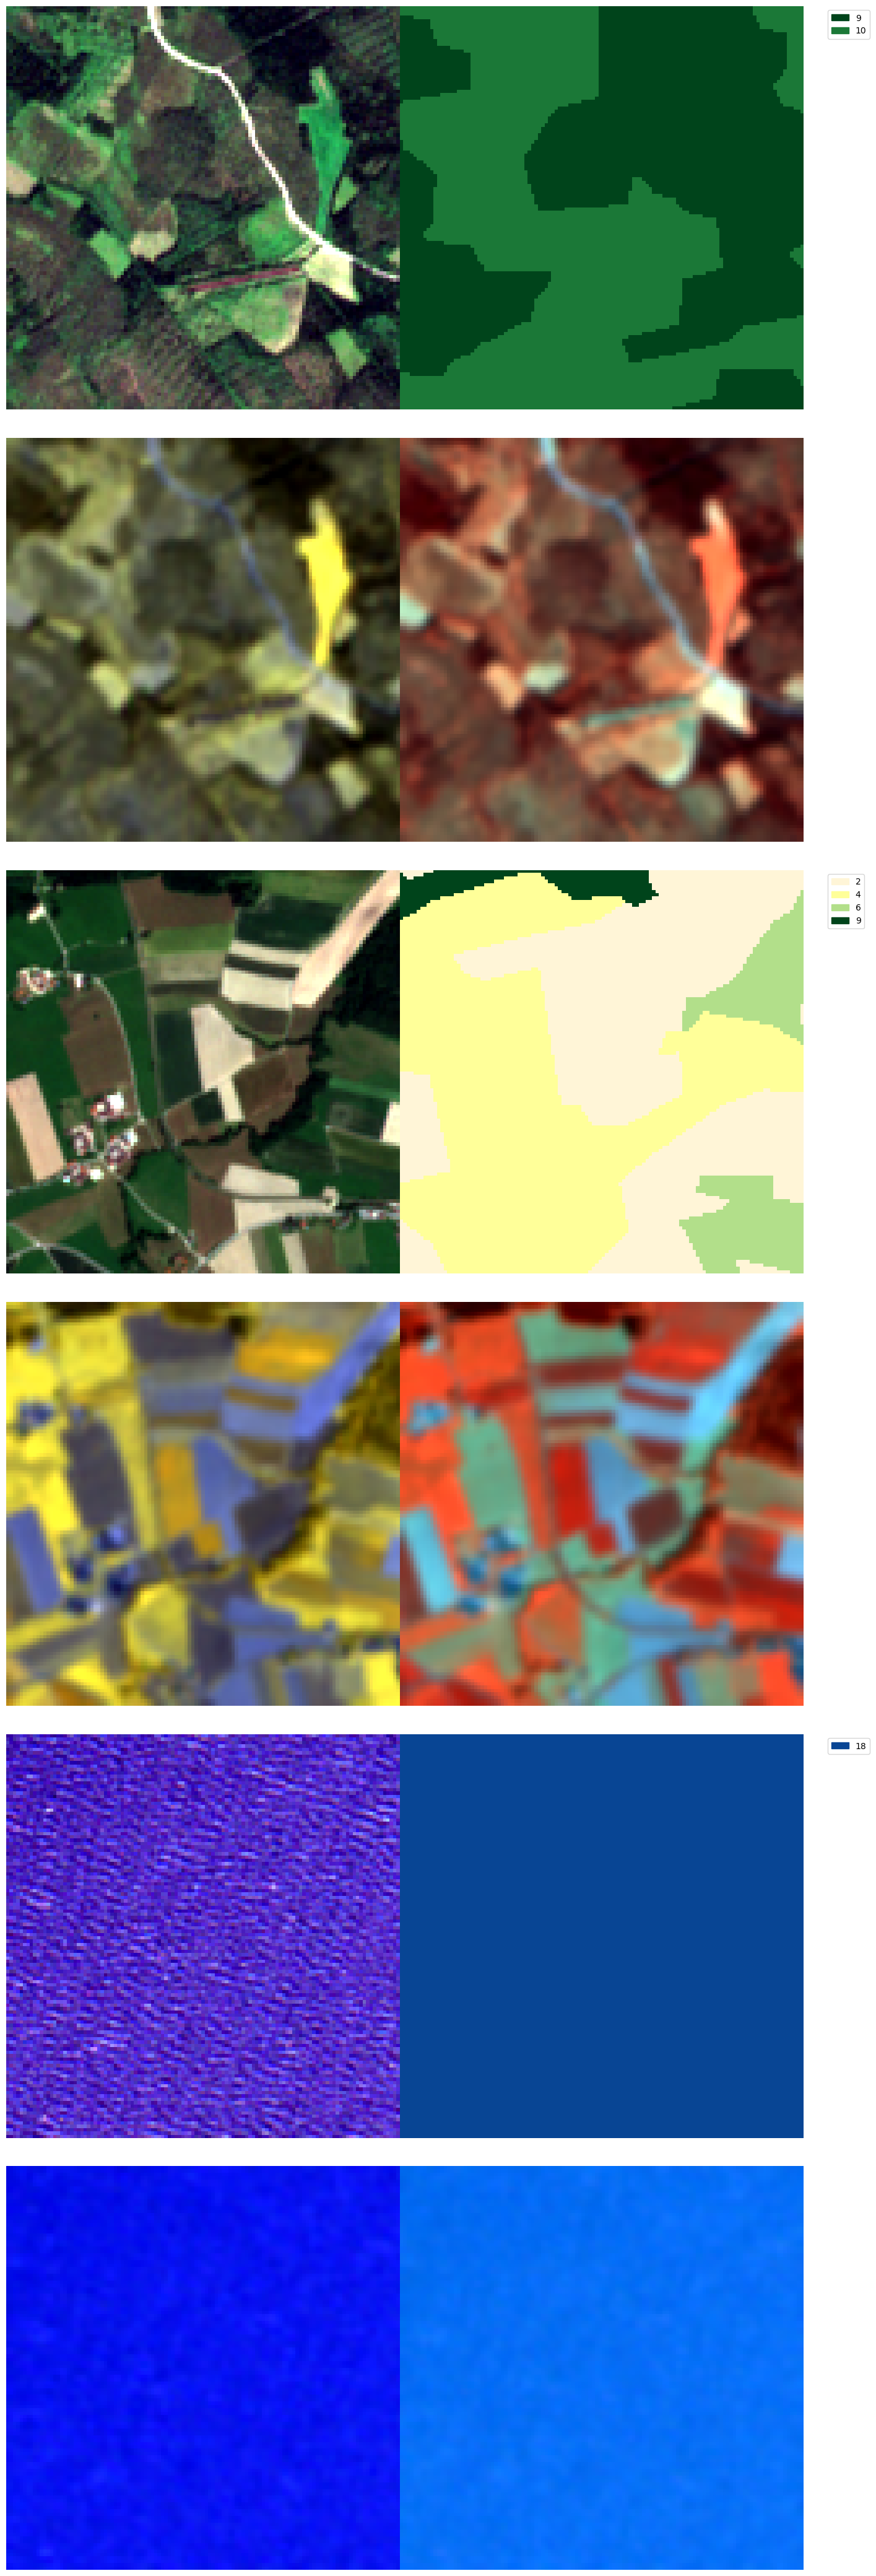

In [25]:
N = 3
idxs = np.random.randint(len(ds), size=N)
#idxs = range(N)

images = []
for idx in idxs:
    img, mask = ds[idx]
    images.extend([quant_norm(img[band_indices['true_color'], :, :]),
                   mask,
                   quant_norm(img[band_indices['red_edge'], :, :]),
                   #quant_norm(img[band_indices['vegetation'], :, :]),
                   quant_norm(img[band_indices['moisture_composite'], :, :])
                   ])

plot_images(images, id_to_class=ds.CLASSES, dataset_name="reben", ncols=2)

In [ ]:
band_indices['vegetation']

[0, 1, 2]